## Rigid Body Motion and 3D Graph Visualization

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

The functions bellow are just to help ploting and visualization. They are definitions of functions that are going to be used latter.

In [ ]:
# @title
def set_plot(ax=None,figure = None,lim=[-2,2]):
    if figure ==None:
        figure = plt.figure(figsize=(8,8))
    if ax==None:
        ax = plt.axes(projection='3d')

    ax.set_xlim(lim)
    ax.set_xlabel("x axis")
    ax.set_ylim(lim)
    ax.set_ylabel("y axis")
    ax.set_zlim(lim)
    ax.set_zlabel("z axis")
    return ax

#adding quivers to the plot
def draw_arrows(point,base,axis,length=1.5):
    # The object base is a matrix, where each column represents the vector
    # of one of the axis, written in homogeneous coordinates (ax,ay,az,0)

    # Plot vector of x-axis
    axis.quiver(point[0],point[1],point[2],base[0,0],base[1,0],base[2,0],color='red',pivot='tail',  length=length)
    # Plot vector of y-axis
    axis.quiver(point[0],point[1],point[2],base[0,1],base[1,1],base[2,1],color='green',pivot='tail',  length=length)
    # Plot vector of z-axis
    axis.quiver(point[0],point[1],point[2],base[0,2],base[1,2],base[2,2],color='blue',pivot='tail',  length=length)

    return axis


### Setting printing options
np.set_printoptions(formatter={'float': lambda x: "{0:0.3f}".format(x)})
np.set_printoptions(precision=3,suppress=True)

## Base vectors representation
#### Defining the 3D vectors e1, e2 and e3, and the origin (0,0,0) in homogeneous coordinates.


Cartesian base: 
 [[1 0 0]
 [0 1 0]
 [0 0 1]
 [0 0 0]]
Origin: 
 [[0]
 [0]
 [0]
 [1]]
Camera: 
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]
World: 
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]


Text(0.5, 0.92, 'Camera and World Reference Frames')

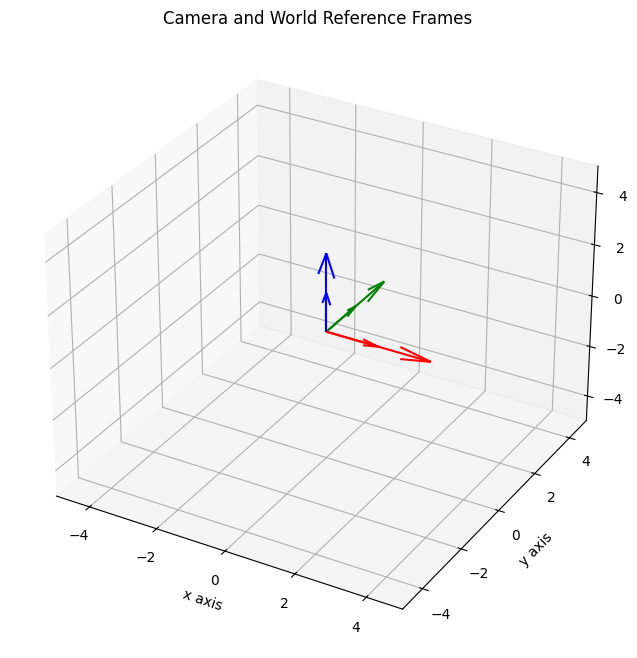

In [ ]:
# @title
# base vector values
e1 = np.array([[1],[0],[0],[0]]) # X
e2 = np.array([[0],[1],[0],[0]]) # Y
e3 = np.array([[0],[0],[1],[0]]) # Z
base = np.hstack((e1,e2,e3))

print('Cartesian base: \n',base)
#origin point
origin =np.array([[0],[0],[0],[1]])

print('Origin: \n',origin)

# You can also consider the camera as an object composed by its base and origin
# Then you can transform such object whenever you want to rotate or translate the camera
cam  = np.hstack([base,origin])


# We are also going to create a reference frame to the world
# Until this moment both reference frames are just the same
world = np.hstack([base,origin])

print ('Camera: \n', cam)
print ('World: \n', world)

# Ploting the world reference frame and the camera frame

axis = set_plot(lim=[-5,5])
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis = draw_arrows(cam[:,-1],cam[:,0:3],axis,1.5)
axis.set_title("Camera and World Reference Frames")

## Defining Rigid Body Transformations as functions



In [ ]:
# @title
# Translation

def move (dx,dy,dz):
    T = np.eye(4)
    T[0,-1]=dx
    T[1,-1]=dy
    T[2,-1]=dz
    return T


# Rotation
# From the first example and from the definition of the rotations around each axis create the other
# rotaiton functions

from math import pi,cos,sin

def z_rotation(angle):
  angle = angle*pi/180
  rotation_matrix=np.array([[cos(angle),-sin(angle),0,0],
                            [sin(angle),cos(angle),0,0],
                            [0,0,1,0],
                            [0,0,0,1]])
  return rotation_matrix

def x_rotation(angle):
  angle = angle*pi/180
  rotation_matrix=np.array([[1,0,0,0],
                            [0,cos(angle),-sin(angle),0],
                            [0,sin(angle),cos(angle),0],
                            [0,0,0,1]])
  return rotation_matrix

def y_rotation(angle):
  angle = angle*pi/180
  rotation_matrix=np.array([[cos(angle),0,sin(angle),0],
                            [0,1,0,0],
                            [-sin(angle), 0, cos(angle),0],
                            [0,0,0,1]])
  return rotation_matrix

## Let's move a 3D point and a 3D vector

Initial point: 
 [-4  8  3  1]
Translation Matrix: 
 [[ 1.  0.  0.  6.]
 [ 0.  1.  0. -3.]
 [ 0.  0.  1.  5.]
 [ 0.  0.  0.  1.]]
Translated point: 
 [2. 5. 8. 1.]


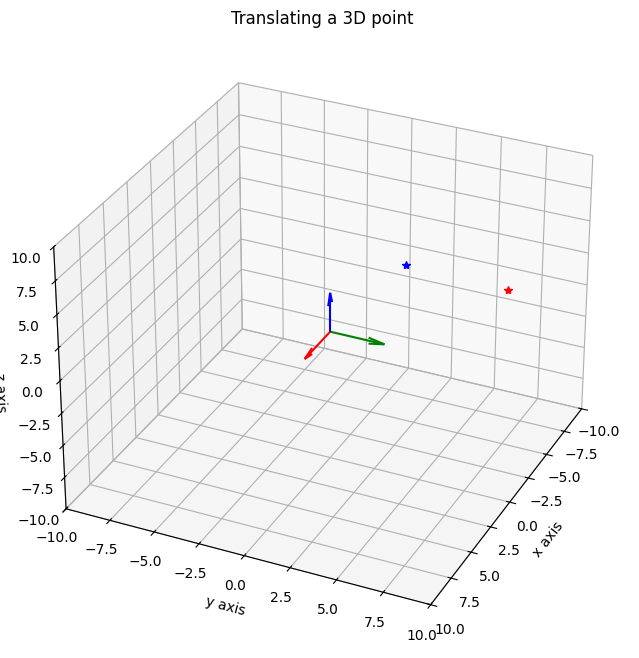

In [ ]:
# @title
# Create a 3D point with the coordinates: (-4, 8, 3, 1)
# Print the point so you can compare later

p3Di = np.array([-4, 8, 3, 1])
print('Initial point: \n', p3Di)

# Create a Translation Matrix with dx= 6, dy= -3, dz= 5)
# Print the matrix so you can see how it is defined

T = move(6,-3,5)
print('Translation Matrix: \n', T)

# Translate the point and print the result to compare with the initial point

p3Dt = np.dot(T,p3Di)
print('Translated point: \n', p3Dt)

# Let's plot the initial and translated point in the world frame
axis = set_plot(lim=[-10,10])
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis.plot3D(p3Di[0],p3Di[1],p3Di[2],'*r')
axis.plot3D(p3Dt[0],p3Dt[1],p3Dt[2],'*b')
axis.set_title('Translating a 3D point')
axis.view_init(elev=30, azim=25)

Initial vector: 
 [-4  8  3  0]
Translation Matrix: 
 [[ 1.  0.  0.  6.]
 [ 0.  1.  0. -3.]
 [ 0.  0.  1.  5.]
 [ 0.  0.  0.  1.]]
Translated point: 
 [-4.  8.  3.  0.]


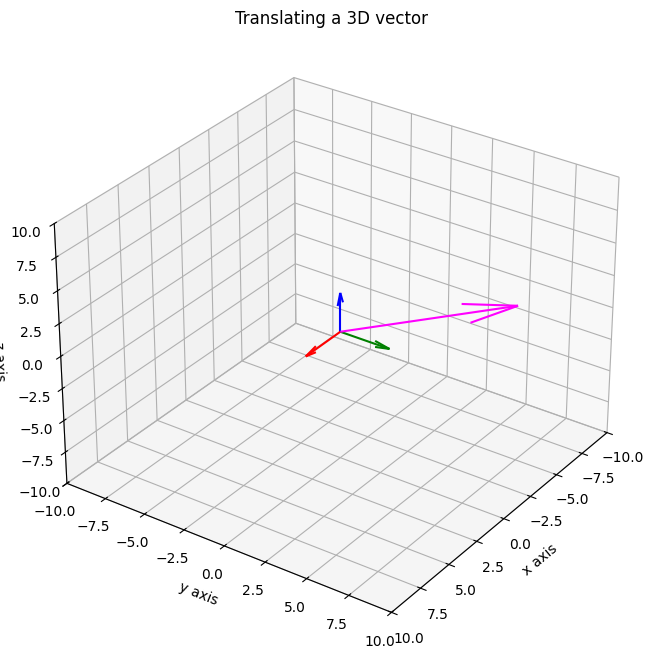

In [ ]:
# @title
# Create a 3D pointvector with the coordinates: (-4, 8, 3, 0)
# Print the point so you can compare later

v3Di = np.array([-4, 8, 3 , 0])
print('Initial vector: \n', v3Di)

# Create a Translation Matrix with dx= 6, dy= -3, dz= 5)
# Print the matrix so you can see how it is defined

T = move(6, -3, 5)
print('Translation Matrix: \n', T)

# Translate the vector and print the result to compare with the initial vector

v3Dt = T@v3Di
print('Translated point: \n', v3Dt)


# Let's plot the initial and translated vector in the world frame
axis = set_plot(lim=[-10,10])
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis.quiver(0,0,0,v3Di[0],v3Di[1],v3Di[2],color='magenta',pivot='tail',  length=1)
axis.quiver(0,0,0,v3Dt[0],v3Dt[1],v3Dt[2],color='orange',pivot='tail',  length=1)
axis.set_title('Translating a 3D vector')
axis.view_init(elev=30, azim=35)

### Attention: Did the vector change?
# The vector doest not change because of the last cordinate, the homogenius cordinate 0
# It block the vector to move

## Let's rotate a 3D point and a 3D vector

Initial point: 
 [4 4 0 1]
Rotation Matrix: 
 [[ 1.  0.  0.  6.]
 [ 0.  1.  0. -3.]
 [ 0.  0.  1.  5.]
 [ 0.  0.  0.  1.]]
Rotated point: 
 [0. 4. 4. 1.]


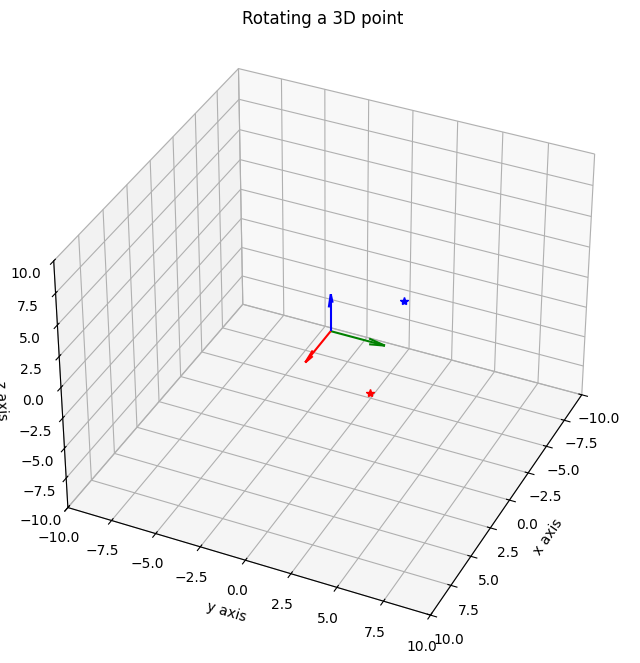

In [ ]:
# @title
# Create a 3D point with the coordinates: (4, 4, 0, 1)
# Print the point so you can compare later

p3Di = np.array([4, 4, 0, 1])
print('Initial point: \n', p3Di)

# Create a Rotation Matrix around the Y-axis of -90 degrees
# Print the matrix so you can see how it is defined

Ry = y_rotation(-90)
print('Rotation Matrix: \n', T)

# Rotate the point and print the result to compare with the initial point

p3Dr = Ry@p3Di
print('Rotated point: \n', p3Dr)

# Let's plot the initial and translated point in the world frame
axis = set_plot(lim=[-10,10])
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis.plot(p3Di[0],p3Di[1],p3Di[2],'*r')
axis.plot(p3Dr[0],p3Dr[1],p3Dr[2],'*b')
axis.set_title('Rotating a 3D point')
axis.view_init(elev=35, azim=25)

Initial vector: 
 [4 4 0 0]
Rotation Matrix: 
 [[ 1.  0.  0.  6.]
 [ 0.  1.  0. -3.]
 [ 0.  0.  1.  5.]
 [ 0.  0.  0.  1.]]
Rotated vector: 
 [0. 4. 4. 0.]


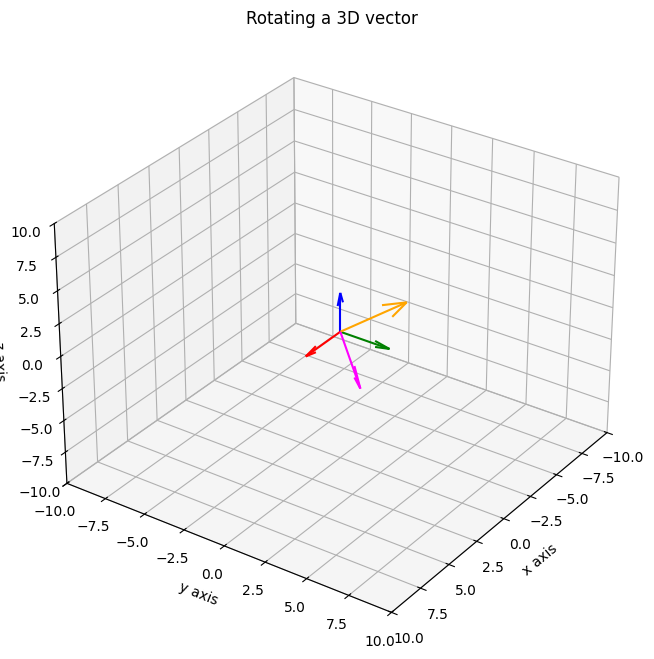

In [ ]:
# @title
# Create a 3D vector with the coordinates: (4, 4, 0, 0)
# Print the point so you can compare later

v3Di = np.array([4, 4, 0, 0])
print('Initial vector: \n', v3Di)

# Create a Rotation Matrix around the Y-axis of -90 degrees
# Print the matrix so you can see how it is defined

Ry = y_rotation(-90)
print('Rotation Matrix: \n', T)

# Rotate the vector and print the result to compare with the initial vector

v3Dr = Ry@v3Di
print('Rotated vector: \n', v3Dr)


# Let's plot the initial and translated vector in the world frame
axis = set_plot(lim=[-10,10])
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis.quiver(0,0,0,v3Di[0],v3Di[1],v3Di[2],color='magenta',pivot='tail',  length=1)
axis.quiver(0,0,0,v3Dr[0],v3Dr[1],v3Dr[2],color='orange',pivot='tail',  length=1)
axis.set_title('Rotating a 3D vector')
axis.view_init(elev=30, azim=35)

## Now let's create and plot an object

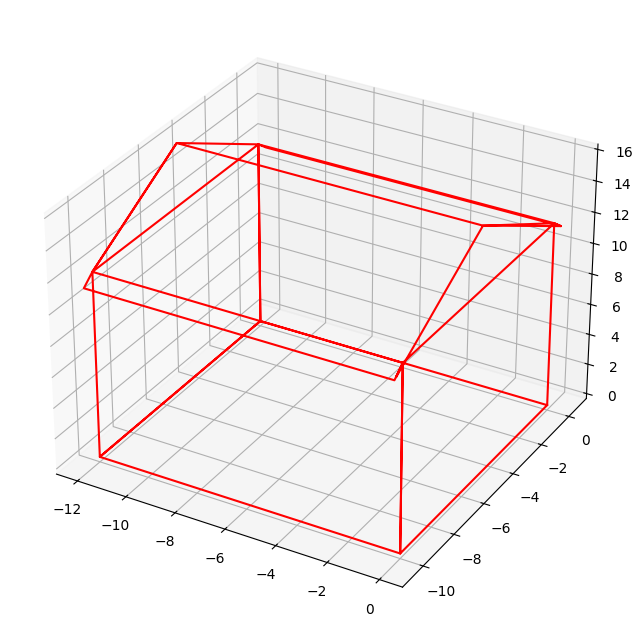

In [ ]:
# @title
# Create a house
house = np.array([[0,         0,         0],
                  [0,  -10.0000,         0],
                  [0, -10.0000,   12.0000],
                  [0,  -10.4000,   11.5000],
                  [0,   -5.0000,   16.0000],
                  [0,         0,   12.0000],
                  [0,    0.5000,   11.4000],
                  [0,         0,   12.0000],
                  [0,         0,         0],
                  [-12.0000,         0,         0],
                  [-12.0000,   -5.0000,         0],
                  [-12.0000,  -10.0000,         0],
                  [0,  -10.0000,         0],
                  [0,  -10.0000,   12.0000],
                  [-12.0000,  -10.0000,   12.0000],
                  [-12.0000,         0,   12.0000],
                  [0,         0,   12.0000],
                  [0,  -10.0000,   12.0000],
                  [0,  -10.5000,   11.4000],
                  [-12.0000,  -10.5000,   11.4000],
                  [-12.0000,  -10.0000,   12.0000],
                  [-12.0000,   -5.0000,   16.0000],
                  [0,   -5.0000,   16.0000],
                  [0,    0.5000,   11.4000],
                  [-12.0000,    0.5000,   11.4000],
                  [-12.0000,         0,   12.0000],
                  [-12.0000,   -5.0000,   16.0000],
                  [-12.0000,  -10.0000,   12.0000],
                  [-12.0000,  -10.0000,         0],
                  [-12.0000,   -5.0000,         0],
                  [-12.0000,         0,         0],
                  [-12.0000,         0,   12.0000],
                  [-12.0000,         0,         0]])

# We have to transpose the object matrix so we can have the points arranged as:
#  house = [ x1, x2, ... ,xn
#            y1, y2, ... ,yn
#            z1, z2, ... ,zn]

house = house.T
# or house = np.transpose(house)

# Representing the object in homogeneous coordinates
# Create row of ones
num_columns = np.size(house,1)
ones_line = np.ones(num_columns)

# Add to the house matrix to represent the house in homogeneous coordinates
house = np.vstack([house, ones_line])

# Plotting the house
figure = plt.figure(figsize=(8,8))
ax0 = plt.axes(projection='3d')
ax0.plot3D(house[0,:], house[1,:], house[2,:], 'red')

## Transforming the house

Translation Matrix: 
 [[ 1.  0.  0. 20.]
 [ 0.  1.  0.  4.]
 [ 0.  0.  1. 30.]
 [ 0.  0.  0.  1.]]
Rotation Matrix: 
 [[ 0.707 -0.707  0.     0.   ]
 [ 0.707  0.707  0.     0.   ]
 [ 0.     0.     1.     0.   ]
 [ 0.     0.     0.     1.   ]]
Rotation Matrix: 
 [[ 0.  0.  1.  0.]
 [ 0.  1.  0.  0.]
 [-1.  0.  0.  0.]
 [ 0.  0.  0.  1.]]


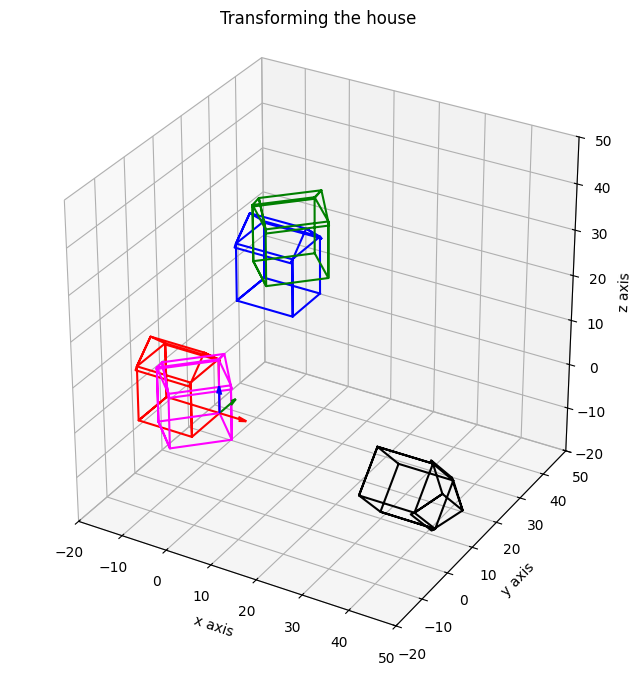

In [ ]:
# @title
#Translate the house with dx=20, dy=4, dz=30
T = move(20, 4, 30)
print('Translation Matrix: \n',T)
new_house = T@house


# Let's create a new figure with the original house and the world reference frame
ax0 = set_plot(lim=[-20,50])
ax0 = draw_arrows(world[:,-1],world[:,0:3],ax0,6)
#plot original house in red
ax0.plot3D(house[0,:], house[1,:], house[2,:], 'red')
ax0.set_aspect('equal')
ax0.set_title('Transforming the house')

# Now plot the translated house in blue, in the same figure so you can see what happened
ax0.plot3D(new_house[0,:], new_house[1,:], new_house[2,:], 'blue')

# Rotate the ORIGINAL house along the z-axis by 45 degrees
Rz = z_rotation(45)
print('Rotation Matrix: \n',Rz)
rotation_house = Rz@house


# Now plot the rotated house in magenta, in the same figure
ax0.plot3D(rotation_house[0,:], rotation_house[1,:], rotation_house[2,:], 'magenta')


# Rotate the TRANSLATED house along the z-axis by 45 degrees
Rz = z_rotation(45)
rotation_house_translated = Rz@new_house


# Now plot the rotated house in green, in the same figure
ax0.plot3D(rotation_house_translated[0,:], rotation_house_translated[1,:], rotation_house_translated[2,:], 'green')


# Now rotate the latest house along the y-axis by 90 degrees
Ry = y_rotation(90)
print('Rotation Matrix: \n',Ry)
rotation_house_translated_2 = Ry@rotation_house_translated


# Now plot the new house in black, in the same figure
ax0.plot3D(rotation_house_translated_2[0,:], rotation_house_translated_2[1,:], rotation_house_translated_2[2,:], 'black')

# Attention
### We could also combine all the transformations first and then apply to the house

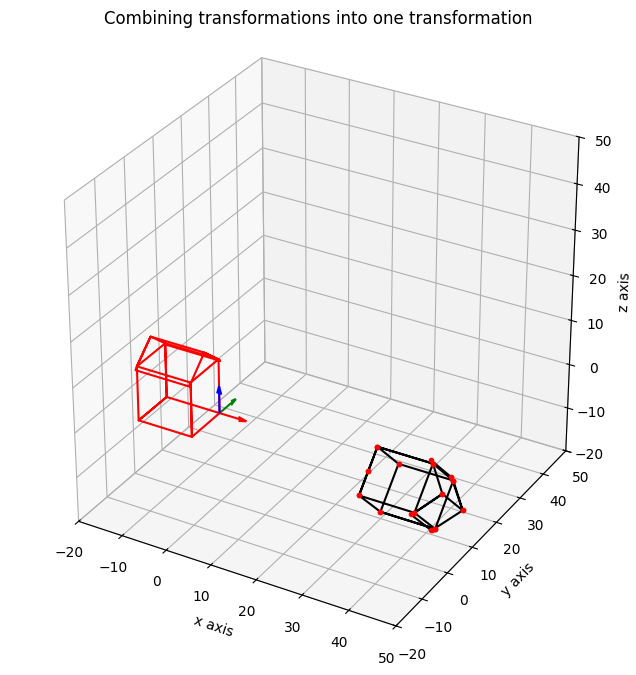

In [ ]:
# @title
T = move(20,4,30)
Rz = z_rotation(45)
Ry = y_rotation(90)

new_house2 = T@house
new_house3 = Rz@new_house2
new_house4 = Ry@new_house3

M1 = Ry@Rz@T
new_house5 = M1@house

# Let's create a new figure with the original house and the world reference frame
ax0 = set_plot(lim=[-20,50])
ax0 = draw_arrows(world[:,-1],world[:,0:3],ax0,6)
#plot original house in red
ax0.plot3D(house[0,:], house[1,:], house[2,:], 'red')
ax0.set_aspect('equal')
ax0.set_title('Combining transformations into one transformation')

ax0.plot3D(new_house4[0,:],new_house4[1,:],new_house4[2,:], 'black')
ax0.plot3D(new_house5[0,:],new_house5[1,:],new_house5[2,:], '.r')

### The order of the transformations matters!!!!!

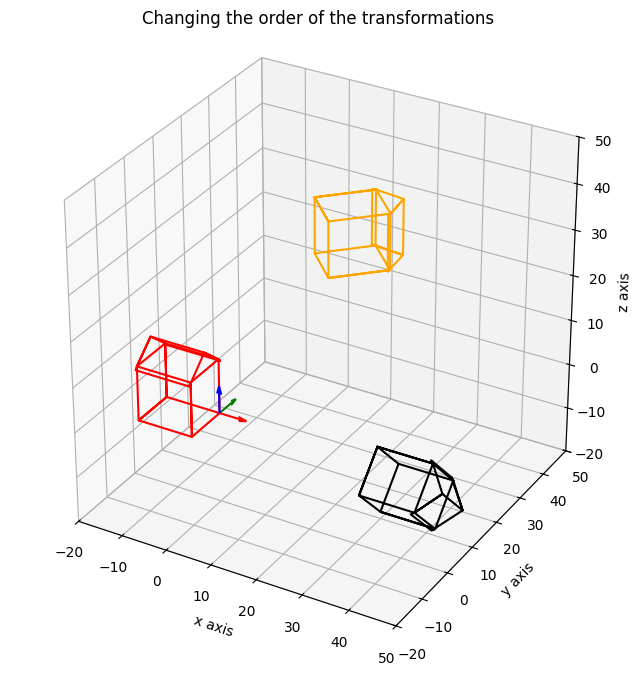

In [ ]:
# @title
M2 = Rz@T@Ry
new_house6 = M2@house
# Let's create a new figure with the original house and the world reference frame
ax0 = set_plot(lim=[-20,50])
ax0 = draw_arrows(world[:,-1],world[:,0:3],ax0,6)
#plot original house in red
ax0.plot3D(house[0,:], house[1,:], house[2,:], 'red')
ax0.set_aspect('equal')

ax0.plot3D(new_house4[0,:],new_house4[1,:],new_house4[2,:], 'black')
ax0.plot3D(new_house6[0,:],new_house6[1,:],new_house6[2,:], 'orange')
ax0.set_title('Changing the order of the transformations')

plt.show()

## Now let's move the camera as an object


Rx:
 [[ 1.  0.  0.  0.]
 [ 0.  0.  1.  0.]
 [ 0. -1.  0.  0.]
 [ 0.  0.  0.  1.]] 

Translation:
 [[1. 0. 0. 3.]
 [0. 1. 0. 3.]
 [0. 0. 1. 3.]
 [0. 0. 0. 1.]] 

New cam: 
 [[ 1.  0.  0.  3.]
 [ 0.  0.  1.  3.]
 [ 0. -1.  0.  3.]
 [ 0.  0.  0.  1.]] 



Text(0.5, 0.92, 'Camera and World Reference Frames')

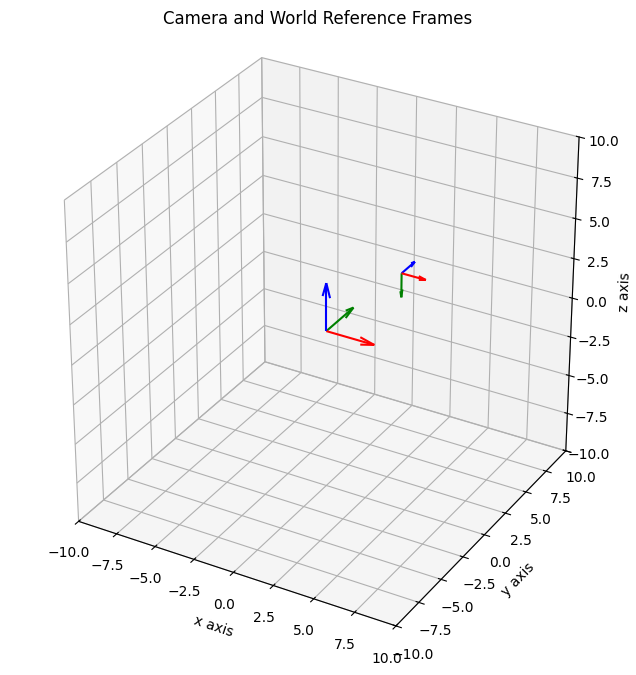

In [ ]:
# @title
# Define rotation
Rx = x_rotation(-90)
print('Rx:\n',Rx,'\n')

# Define translation
T = move (3,3,3)
print('Translation:\n', T,'\n')

# Combining the transforamtions
M = T@Rx

# or M = np.dot(T,Rx)

# Transforming the camera

new_cam = M@cam
print('New cam: \n', new_cam, '\n' )

# Ploting the world reference frame and the camera frame

axis = set_plot(lim=[-10,10])
axis.set_aspect('equal')
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis = draw_arrows(new_cam[:,-1],new_cam[:,0:3],axis,1.5)
axis.set_title("Camera and World Reference Frames")

## Let's apply more transformations to the camera frame

Text(7.8571067811865465, 4.15, 'Cam05')

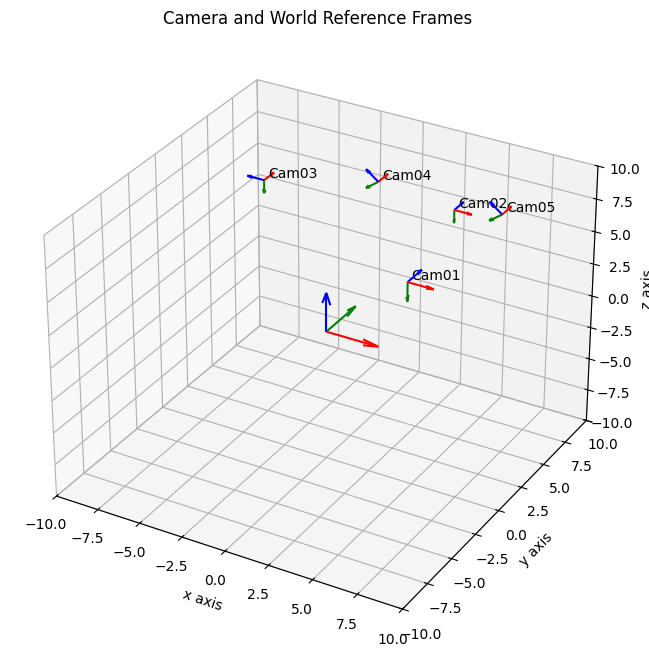

In [ ]:
# @title
# Let's use the new_camera as the first iteration

cam01 = new_cam

# Translate cam01 with (1, 3, 4) and store in cam02
T = move (1,3,4)
cam02 = T@cam01

# Follow the example above to create your code to rotate cam02 90 degrees
# around the Z-axis and store in cam03
T = z_rotation(90)
cam03 = T@cam02

# Now rotate cam03 45 degrees around the Y-axis and store in cam04
T = y_rotation(45)
cam04 = T@cam03

# Now translate cam04 (7,0,0) and store in cam05
T = move(7, 0, 0)
cam05 = T@cam04


# Let's plot all the steps
axis = set_plot(lim=[-10,10]) # adicionei porque não estava mostrando nada
# First camera
axis = draw_arrows(world[:,-1],world[:,0:3],axis,3)
axis = draw_arrows(cam01[:,-1],cam01[:,0:3],axis,1.5)
axis.set_title("Camera and World Reference Frames")
axis.text(cam01[0,3]+.15,cam01[1,3]+.15,cam01[2,3]+.15, "Cam01")
# Platting all the following steps
axis = draw_arrows(cam02[:,3],cam02[:,0:3],axis,length=1.0) # estava com axis 1
axis.text(cam02[0,3]+.15, cam02[1,3]+.15,cam02[2,3]+.15, "Cam02")
axis = draw_arrows(cam03[:,3],cam03[:,0:3],axis,length=1.0) # estava com axis 1
axis.text(cam03[0,3]+.15, cam03[1,3]+.15,cam03[2,3]+.15, "Cam03")
axis = draw_arrows(cam04[:,3],cam04[:,0:3],axis,length=1.0) # estava com axis 1
axis.text(cam04[0,3]+.15, cam04[1,3]+.15,cam04[2,3]+.15, "Cam04")
axis = draw_arrows(cam05[:,3],cam05[:,0:3],axis,length=1.0) # estava com axis 1
axis.text(cam05[0,3]+.15,cam05[1,3]+.15,cam05[2,3]+.15, "Cam05")

# ATTENTION
Because the way we defined our camera, its current state (object) is just the same as its accumulated transformation

In [ ]:
# @title
# Recreating camera
cam = np.eye(4)

# Defining the transformations
Rx = x_rotation(-90)
T = move(2,7,5)

# Applying the transformations to the camera
cam = T@Rx@cam

# Combining the transformations
Mcam = np.dot(T,Rx)

print('Camera :\n',cam)
print('Accumulated transformation:\n',Mcam)

Camera :
 [[ 1.  0.  0.  2.]
 [ 0.  0.  1.  7.]
 [ 0. -1.  0.  5.]
 [ 0.  0.  0.  1.]]
Accumulated transformation:
 [[ 1.  0.  0.  2.]
 [ 0.  0.  1.  7.]
 [ 0. -1.  0.  5.]
 [ 0.  0.  0.  1.]]


#  IMPORTANT
#### Functions to change the camera in its own reference frame

In [ ]:
# @title
# What you should do to make a camera translate or rotate in its own reference frame?
  # We should translate the camera to the world reference frame origin and apply the
  # translation or rotation transformation. Then, we translate the transformed
  # camera to its original position

# Define a set of functions to perfom 3D translation and rotation around the x, Y and Z axes


# Translation in its own frame
# Consider receiving as input the current camera frame and the (dx,dy,dz) desired displacement
# Return as output the transformation matrix (if you want) and the new camera frame

def own_move (dx,dy,dz,cam):
  # define the translation to the world reference frame and the translation back to the camera reference
  world_reference_translation = move(-cam[0,-1], -cam[1,-1], -cam[2,-1])
  move_camera_origin_translation = move(cam[0,-1], cam[1,-1], cam[2,-1])
  cam = world_reference_translation@cam
  # apply the translation
  T = move(dx, dy, dz)
  cam = T@cam
  # return to the camera reference frame
  cam = move_camera_origin_translation@cam

  return T, cam

# Rotation around its own Z-axis
# Consider receiving as input the current camera frame and the angle for the desired rotation
# Return as output the transformation matrix (if you want) and the new camera frame

def own_z_rotation(angle, cam):
  id = np.eye(4)
  Rz = z_rotation(angle)

  rotation = Rz@id

  return Rz, cam@rotation

# Rotation around its own X-axis
# Consider receiving as input the current camera frame and the angle for the desired rotation
# Return as output the transformation matrix (if you want) and the new camera frame

def own_x_rotation(angle, cam):
  id = np.eye(4)
  Rx = x_rotation(angle)

  rotation = Rx@id

  return Rx, cam@rotation

# Rotation around its own Y-axis
# Consider receiving as input the current camera frame and the angle for the desired rotation
# Return as output the transformation matrix (if you want) and the new camera frame

def own_y_rotation(angle, cam):
  id = np.eye(4)
  Ry = y_rotation(angle)

  rotation = Ry@id

  return Ry, cam@rotation


#### Let's try some of the functions

<Axes3D: title={'center': 'Transforming the camera within its own frame'}, xlabel='x axis', ylabel='y axis', zlabel='z axis'>

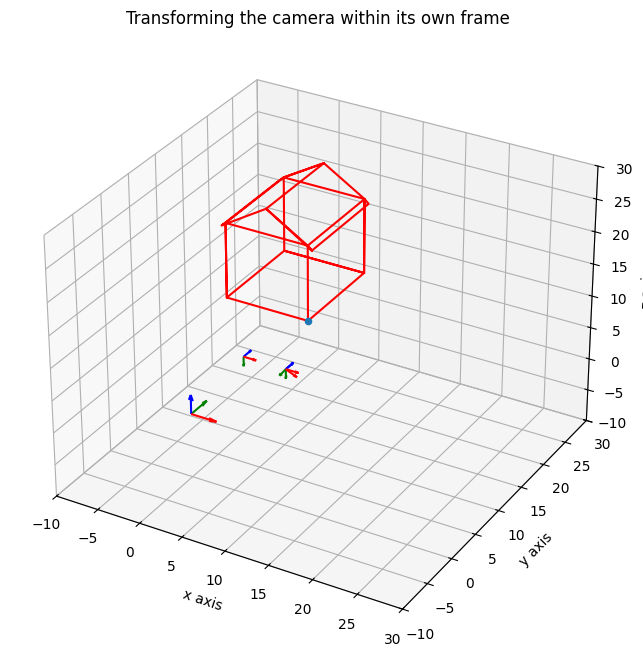

In [ ]:
# @title
# Rotating and moving the house to a desired position
Rz = z_rotation(-90)
T = move(2,20,2)
house01 = T@Rz@house

# Plotting the current scene
axis = set_plot(lim=[-10,30])
axis.set_title('Transforming the camera within its own frame')
axis.plot3D(house01[0,:], house01[1,:], house01[2,:], 'red')
# Plotting the house corner
axis.scatter(house01[0,0], house01[1,0], house01[2,0],'b')
# Plotting the camera and world reference frames
draw_arrows(world[:,-1],world[:,0:3],axis,3)
draw_arrows(cam[:,-1],cam[:,0:3],axis,1.5)

# Move the current camera along its own X-axis of 5 units
# Write your code below
T, cam = own_move(5, 0, 0, cam)

# Plot the new pose of the camera
draw_arrows(cam[:,-1], cam[:,0:3],axis,1.5)



# Rotate the current camera along its own Z-axis by 30 degrees
# Write your code below
T, cam = own_z_rotation(30, cam)



# Plot the new pose of the camera
draw_arrows(cam[:,-1], cam[:,0:3],axis,1.5)